In [1]:
import json
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RandomizedSearchCV

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier

2025-05-17 13:06:40.600596: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 13:06:40.600620: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
print(df['Attack_type'].value_counts())

Attack_type
Normal                   1399624
DDoS_UDP                  121567
DDoS_ICMP                  67939
SQL_injection              50826
DDoS_TCP                   50062
Vulnerability_scanner      50026
Password                   49933
DDoS_HTTP                  48544
Uploading                  36957
Backdoor                   24026
Port_Scanning              19977
XSS                        15068
Ransomware                  9689
Fingerprinting               853
MITM                         358
Name: count, dtype: int64


In [6]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [7]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [8]:
print(df['Attack_type'].value_counts())

Attack_type
0     1399624
13     121567
14      67939
4       50826
6       50062
9       50026
7       49933
5       48544
2       36957
10      24026
8       19977
11      15068
3        9689
12        853
1         358
Name: count, dtype: int64


In [9]:
mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

In [10]:
mi_scores.head(10)

tcp.dstport      0.870595
dns_0            0.788073
tcp.ack_raw      0.745540
tcp.ack          0.722140
mqtt3_0          0.653018
mqtt1_0          0.652799
mqtt2_0          0.652175
http3_encoded    0.622944
http1_encoded    0.609375
dns_encoded      0.606070
dtype: float64

In [11]:
k = 30
selected_features = mi_scores.head(k).index.tolist()

In [12]:
X = X[selected_features]

In [13]:
X = X.to_numpy()
y = y.to_numpy()

In [14]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
splits = list(skf.split(X, y))
selected_idx = splits[0][1]

X_partition = X[selected_idx]
y_partition = y[selected_idx]

# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X_partition, y_partition, test_size=0.2, random_state=42)
# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [15]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (136181, 30)
X_val shape: (19455, 30)
X_test shape: (38909, 30)


In [16]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [17]:
param_grid = {
    "filters": [16, 32, 64, 128],               # Number of filters in the Conv1D layer
    "kernel_size": [3, 5, 7],                   # Size of the convolutional kernel
    # "pool_size": [2, 3],                        # Size of the pooling window
    "dropout_rate": [0.2, 0.3, 0.5],            # Dropout rate for regularization
    "dense_units": [32, 64, 128],               # Number of units in the dense layer
    "learning_rate": [1e-4, 1e-3, 5e-4],        # Learning rate for the optimizer
    "batch_size": [16, 32, 64],                 # Batch size for training
    "epochs": [15],                             # Number of training epochs
}

In [18]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=15,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=1e-4,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [19]:
keras_classifier = KerasClassifier(
    build_fn=model_1d_cnn,
    input_shape=(X_train.shape[1], 1),
    num_classes=15,
    verbose=0
)

early_stop = EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
)

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

search_cv = GridSearchCV(
        estimator=keras_classifier,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=14,
        refit=True,
        verbose=2,
        return_train_score=True
)

# search_cv = RandomizedSearchCV(estimator=keras_classifier,
#                                    param_distributions=param_grid,
#                                    n_iter=100,  # Number of parameter settings sampled
#                                    scoring='accuracy',
#                                    cv=cv,
#                                    n_jobs=12,
#                                    refit=True,
#                                    verbose=2,
#                                    return_train_score=True,
#                                    random_state=42)

/tmp/ipykernel_477178/469087226.py:1: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead.
  keras_classifier = KerasClassifier(


In [20]:
# Train the model
search_cv.fit(X_train, y_train,
                validation_data=(X_val, y_val),
                callbacks=[early_stop])

best_model = search_cv.best_estimator_

Fitting 2 folds for each of 972 candidates, totalling 1944 fits


2025-05-17 13:28:09.778452: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 13:28:09.778500: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-17 13:28:09.836587: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 13:28:09.836626: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-17 13:28:09.968440: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or dire

[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=16, kernel_size=5, learning_rate=0.001; total time= 3.8min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=16, kernel_size=7, learning_rate=0.0005; total time= 4.0min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=32, kernel_size=5, learning_rate=0.0005; total time= 4.3min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=64, kernel_size=5, learning_rate=0.0001; total time= 4.8min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=128, kernel_size=3, learning_rate=0.001; total time= 6.6min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=128, kernel_size=7, learning_rate=0.0005; total time= 5.9min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=15, filters=32, kernel_size=3, learning_rate=0.0005; total time= 4.1min
[CV] END batch_size=16, dense_units=32, d

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
2025-05-17 14:31:40.965412: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 14:31:40.965467: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-17 14:31:43.530074: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-17 14:31:43.533413: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynami

[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=16, kernel_size=5, learning_rate=0.0001; total time= 4.5min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=32, kernel_size=5, learning_rate=0.001; total time= 4.2min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=64, kernel_size=3, learning_rate=0.0005; total time= 4.7min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=128, kernel_size=3, learning_rate=0.0001; total time= 6.6min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=15, filters=128, kernel_size=7, learning_rate=0.001; total time= 6.4min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=15, filters=16, kernel_size=5, learning_rate=0.0005; total time= 3.9min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=15, filters=32, kernel_size=5, learning_rate=0.0001; total time= 4.2min
[CV] END batch_size=16, dense_units=32, d

2025-05-17 14:38:16.125269: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 14:38:16.125334: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-17 14:38:18.928176: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-17 14:38:18.931630: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 14:38:18.932467: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

... (85 outputs left out)

2025-05-17 23:05:09.703924: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 23:05:09.704002: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-17 23:05:12.937858: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-17 23:05:12.942227: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 23:05:12.943388: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

[CV] END batch_size=64, dense_units=32, dropout_rate=0.5, epochs=15, filters=64, kernel_size=3, learning_rate=0.0005; total time= 2.4min
[CV] END batch_size=64, dense_units=32, dropout_rate=0.5, epochs=15, filters=128, kernel_size=3, learning_rate=0.0001; total time= 4.5min
[CV] END batch_size=64, dense_units=32, dropout_rate=0.5, epochs=15, filters=128, kernel_size=7, learning_rate=0.001; total time= 3.7min
[CV] END batch_size=64, dense_units=64, dropout_rate=0.2, epochs=15, filters=32, kernel_size=3, learning_rate=0.001; total time= 1.8min
[CV] END batch_size=64, dense_units=64, dropout_rate=0.2, epochs=15, filters=32, kernel_size=7, learning_rate=0.0005; total time= 2.0min
[CV] END batch_size=64, dense_units=64, dropout_rate=0.2, epochs=15, filters=64, kernel_size=7, learning_rate=0.0001; total time= 3.0min
[CV] END batch_size=64, dense_units=64, dropout_rate=0.2, epochs=15, filters=128, kernel_size=5, learning_rate=0.001; total time= 5.1min
[CV] END batch_size=64, dense_units=64, d

2025-05-17 23:06:52.268590: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 23:06:52.268662: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-17 23:06:55.793999: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-17 23:06:55.797388: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-17 23:06:55.798287: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=15, filters=16, kernel_size=3, learning_rate=0.001; total time= 2.1min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=15, filters=16, kernel_size=7, learning_rate=0.0001; total time= 1.7min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=15, filters=32, kernel_size=5, learning_rate=0.001; total time= 2.1min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=15, filters=64, kernel_size=3, learning_rate=0.0005; total time= 3.3min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=15, filters=128, kernel_size=3, learning_rate=0.0001; total time= 5.9min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=15, filters=128, kernel_size=7, learning_rate=0.001; total time= 4.7min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=15, filters=16, kernel_size=7, learning_rate=0.0005; total time= 1.6min
[CV] END batch_size=64, dense_units

In [21]:
print('Best Hyperparameters:')
print(search_cv.best_params_)

Best Hyperparameters:
{'batch_size': 16, 'dense_units': 128, 'dropout_rate': 0.2, 'epochs': 15, 'filters': 128, 'kernel_size': 7, 'learning_rate': 0.0005}


In [22]:
y_pred = best_model.predict(np.expand_dims(X_test, axis=2))

In [23]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00     28040
                 MITM       1.00      1.00      1.00         7
            Uploading       0.61      0.69      0.65       732
           Ransomware       0.98      0.85      0.91       190
        SQL_injection       0.55      0.89      0.68      1006
            DDoS_HTTP       0.93      0.86      0.89      1014
             DDoS_TCP       0.98      0.92      0.95       982
             Password       0.96      0.27      0.42       992
        Port_Scanning       0.83      1.00      0.91       416
Vulnerability_scanner       0.98      0.88      0.93      1036
             Backdoor       0.95      0.97      0.96       467
                  XSS       0.48      0.81      0.60       277
       Fingerprinting       1.00      0.35      0.52        17
             DDoS_UDP       0.99      1.00      1.00      2432
            DDoS_ICMP       0.99      0.99      0.99  

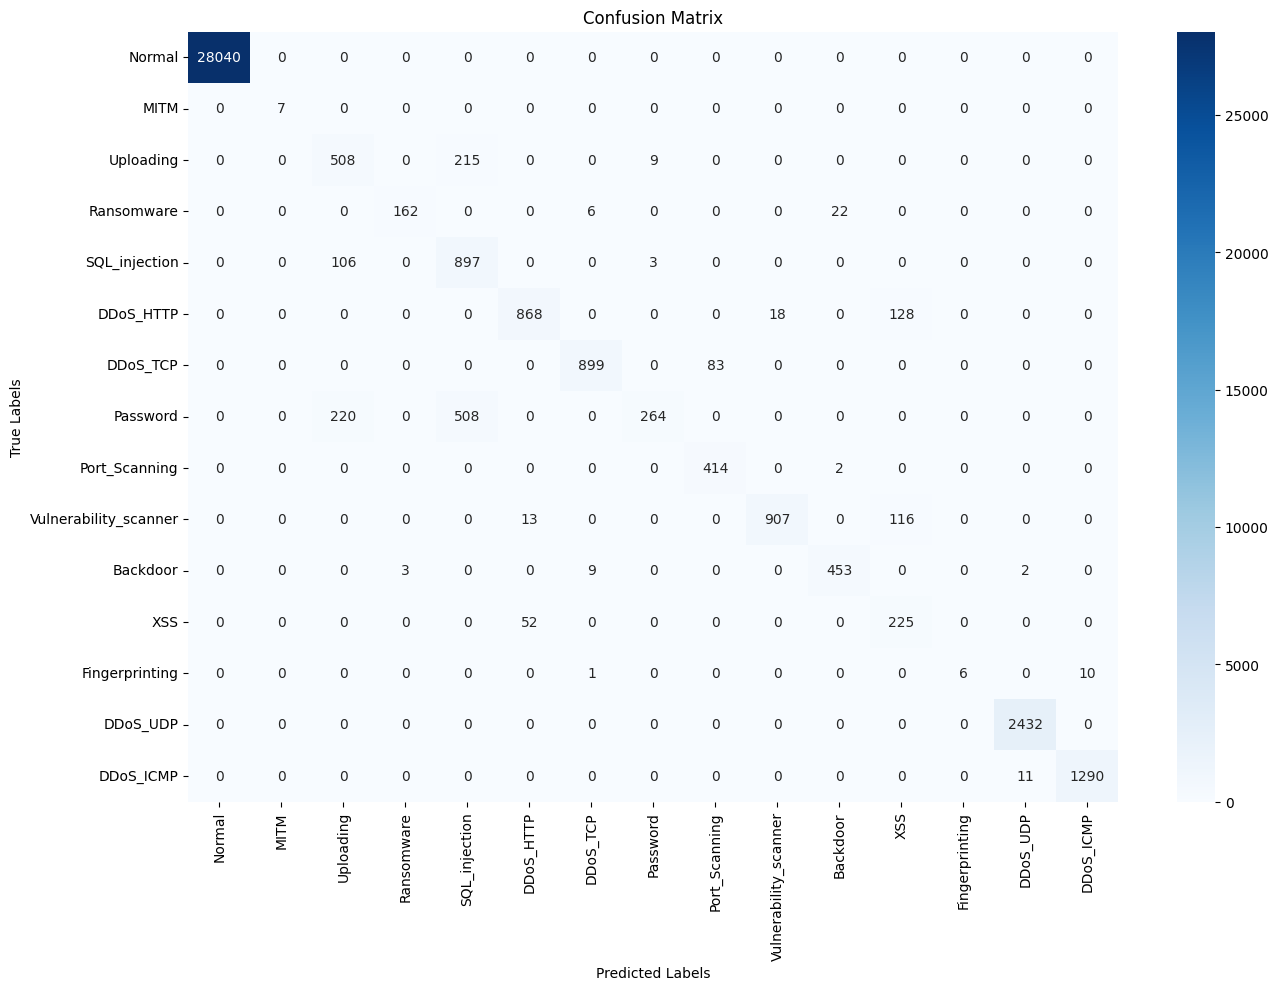

In [24]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.savefig('results/HPT/confusion_matrix_HPT_15.jpg')
plt.show()

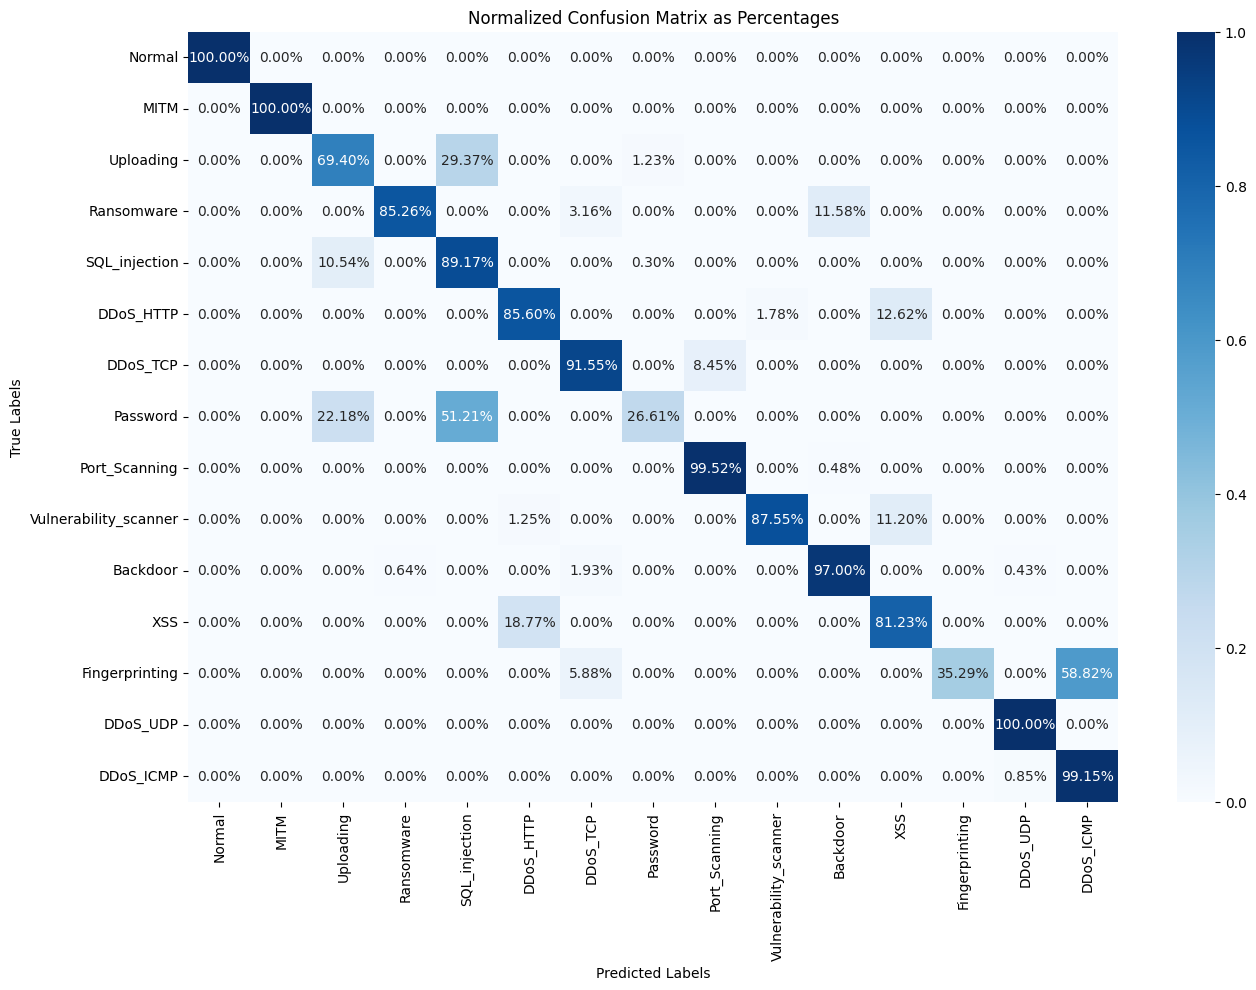

In [25]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.savefig('results/HPT/confusion_matrix_percent_HPT_15.jpg')
plt.show()

In [26]:
best_model.model.save("results/HPT/hpt_1d_cnn_model_15.h5")

In [27]:
with open('results/HPT/HP_1d_cnn_15.json', 'w') as f:
    json.dump(search_cv.best_params_, f)